# A glucose–insulin digital twin, end to end

This notebook is the whole project in one place: the **problem**, the **methods** (with the
theory behind each), the **experiments** (run live here), and the **results**.

It loads the committed data and trained models, so it doesn't retrain everything from
scratch. The full runs are in `scripts/0*.py`. A few cells do train live (a short ODE fit, the
per-patient fine-tuning), and the whole notebook takes a few minutes on a laptop CPU.

I come from signal processing, so I explain the biology in SP terms where I can. Most of it
turns out to be familiar objects: low-pass filters, a bilinear system, a coloured-noise sensor,
and an unknown plant that we identify per patient.

**Everything here is on simulated patients. Nothing in this notebook is medical advice.**

| Part | Sections |
|---|---|
| **I. Problem** | 1 The problem · 2 The data · 3 Task, protocol and metrics |
| **II. Method** | 4 Baselines · 5 Mechanistic model · 6 Hybrid · 7 Neural models · 8 Training · 9 Personalisation and uncertainty · 10 The agent |
| **III. Experiments** | E1 Population forecasting · E2 Personalisation · E3 Uncertainty · E4 Data efficiency · E5 Does the twin respect physiology? · E6 Agent · E7 Distributed training and profiling |
| **IV. Results** | Results table · What it shows · What it doesn't · Next steps |

In [1]:
import os, json, time, copy
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from biotwin.data.dataset import Cohort, standard_sets, make_windows, subset, LH, H, STEPS_PER_DAY, ADAPT_DAYS
from biotwin.evaluate import point_metrics, interval_metrics_gaussian, interval_metrics_from_samples
from biotwin.train import fit, predict

torch.set_num_threads(4)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": 0.3})
CKPT = Path("results/checkpoints")
saved = lambda path: json.loads(Path(f"results/{path}.json").read_text())
print("torch", torch.__version__)

torch 2.11.0


---
# Part I — The problem

## 1. The problem

A person with type-1 diabetes doesn't produce insulin. They wear a **CGM** (continuous
glucose monitor) that reports glucose every 5 minutes, and they deliver insulin themselves:
a slow constant **basal** rate plus **boluses** at meals. Carbs push glucose up and insulin
pulls it down, both with delays of tens of minutes to hours.

| Biology | What it is for us |
|---|---|
| Glucose (mg/dL) | the output $y[n]$, sampled every 5 min |
| CGM sensor | a noisy measurement of it, with coloured (autocorrelated) noise |
| Insulin, carbs | two known inputs $u[n]$, $r[n]$ |
| Absorption from skin or gut | low-pass filters (a few first-order stages in series) |
| Insulin sensitivity | a gain that varies several-fold between people |
| Healthy range | roughly 70–180 mg/dL; below 70 is hypoglycaemia, which is dangerous quickly |

A **digital twin** here is a model of *one* patient that can answer "what if" questions: what
happens over the next hour if they eat 60 g now, or take 2 U of insulin. Technically that's
**forecasting conditioned on planned future inputs**, and the model has to get the *causal*
effect of those inputs right, not only fit the observed data.

The questions the project asks:
1. How much does physics help compared with system identification (ARX) and black-box neural
   networks?
2. Can we personalise the twin to a new patient from a few days of data, with honest error bars?
3. Does the twin respond to interventions in a physiologically correct way?
4. Can an LLM agent use the twin as a tool without making up numbers?

A longer biology primer is in `docs/biology_primer.md`.

## 2. The data

### Where it comes from
Real CGM datasets (OhioT1DM and others) need a data-use agreement, so we use the open-source
**UVA/Padova T1D simulator** through [`simglucose`](https://github.com/jxx123/simglucose)
v0.2.11 (MIT license). It has 30 virtual patients (10 children, 10 adolescents, 10 adults),
each with its own parameter set.

### What the simulator is (the "true plant")
The patient model has **13 states**. Reading `simglucose/patient/t1dpatient.py`:

| Block | States | What's nonlinear about it |
|---|---|---|
| Meal | stomach solid, stomach liquid, gut | the gastric emptying rate depends on how full the stomach is (tanh shape) |
| Glucose | plasma $G_p$, tissue $G_t$ | tissue uptake is Michaelis–Menten, $V_m(X)\,G_t/(K_m+G_t)$; the kidneys excrete glucose above a threshold; liver production falls with glucose and insulin |
| Insulin | plasma, liver | linear |
| Insulin action | action on uptake $X$, and a two-stage delayed action on the liver | multiplies glucose uptake |
| Subcutaneous insulin | 2 depots | linear |
| Sensor site | subcutaneous glucose $G_s$ | a first-order lag of plasma glucose |

### The CGM
The GuardianRT sensor model adds **coloured** noise: an autocorrelated sequence generated
every 15 min, passed through a Johnson transform (non-Gaussian, heavier tails),
cubic-interpolated to 5 min, and clipped to 39–600 mg/dL. That isn't white noise, so expect
slow wobbles that look like real glucose changes.

### Patient behaviour (our code, `src/biotwin/data/simulate.py`)
- 3 main meals and up to 3 snacks a day, with random times and sizes (same structure as
  simglucose's `RandomScenario`).
- Bolus = carbs / carb ratio, with a **±20 % carb-counting error**. **10 % of meals get no
  bolus.** Bolus timing jitters by −10 to +30 min. A correction is added if CGM > 150.
- **Rescue carbs** (15 g) if CGM < 70.

The imperfections are deliberate. If every meal came with an exactly matched, on-time bolus,
insulin and carbs would always move together, and no method could separate their effects
(two perfectly collinear inputs: an identifiability problem).

### What we record
On a 5-minute grid: `cgm` (noisy), `bg` (the noise-free sensor-site glucose $G_s$, used **only**
to measure the noise floor and never as a model input), `insulin` (U per 5 min), `carbs`
(g per 5 min), and the patient's `basal` rate.

One important design choice: the simulator (13 states, several nonlinearities) is **not** the
model we fit (7 states, one bilinear term). If they were the same, the mechanistic approach
would win trivially.

Simulating one patient for one day as a demo:

In [2]:
from biotwin.data.simulate import simulate_patient

t = time.time()
demo = simulate_patient("adult#001", days=1, seed=123)
print(f"simulated 1 day in {time.time() - t:.0f}s;", {k: np.shape(v) for k, v in demo.items() if k != "name"})

simulated 1 day in 4s; {'cgm': (288,), 'bg': (288,), 'insulin': (288,), 'carbs': (288,), 'basal': ()}


The full cohort is 30 patients × 10 days (`scripts/00_simulate.py`, about 15 minutes on 8
cores). It's committed as `data/cohort.npz`.

30 patients, 2880 samples each = 10 days at 5 min


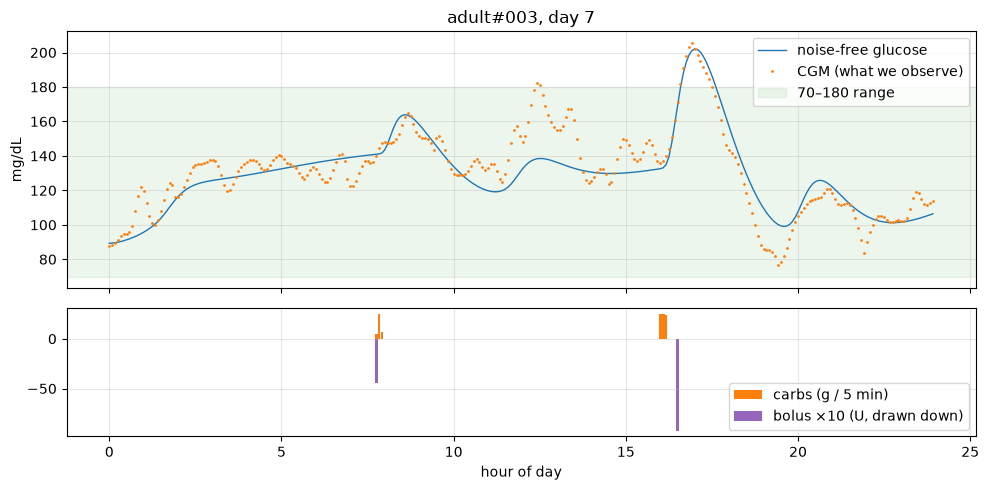

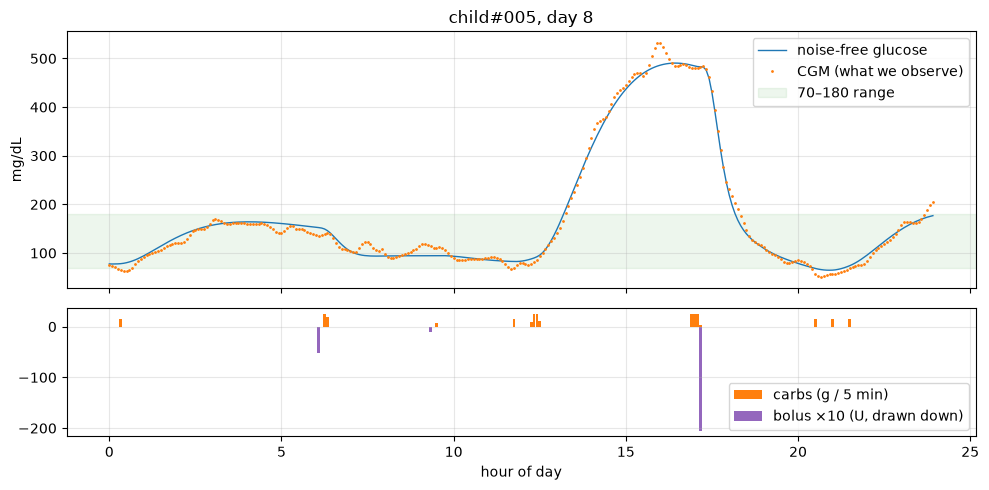

In [3]:
cohort = Cohort.load("data/cohort.npz")
P, T = cohort.cgm.shape
print(f"{P} patients, {T} samples each = {T // STEPS_PER_DAY} days at 5 min")

def plot_day(name, day):
    p = cohort.idx(name)
    sl = slice(day * STEPS_PER_DAY, (day + 1) * STEPS_PER_DAY)
    hours = np.arange(STEPS_PER_DAY) * 5 / 60
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    a1.plot(hours, cohort.bg[p, sl], label="noise-free glucose", lw=1)
    a1.plot(hours, cohort.cgm[p, sl], ".", ms=2, label="CGM (what we observe)")
    a1.axhspan(70, 180, color="g", alpha=0.07, label="70–180 range")
    a1.set_ylabel("mg/dL"); a1.legend(loc="upper right"); a1.set_title(f"{name}, day {day}")
    a2.bar(hours, cohort.carbs[p, sl], width=0.08, label="carbs (g / 5 min)", color="tab:orange")
    a2.bar(hours, -10 * (cohort.insulin[p, sl] - cohort.basal[p]), width=0.08,
           label="bolus ×10 (U, drawn down)", color="tab:purple")
    a2.set_xlabel("hour of day"); a2.legend(loc="lower right")
    plt.tight_layout(); plt.show()

plot_day("adult#003", 7)
plot_day("child#005", 8)

In [4]:
noise = np.sqrt(np.mean((cohort.cgm - cohort.bg) ** 2))
print(f"CGM vs noise-free glucose, RMSE over the cohort: {noise:.1f} mg/dL  <- the sensor noise floor")

groups = {}
for n, row in zip(cohort.names, cohort.cgm):
    groups.setdefault(str(n).split("#")[0], []).append(row)
print(f"\n{'group':11s} {'mean':>6s} {'sd':>6s} {'% <70':>6s} {'% >180':>7s}")
for g, rows in groups.items():
    x = np.concatenate(rows)
    print(f"{g:11s} {x.mean():6.0f} {x.std():6.0f} {100 * (x < 70).mean():6.1f} {100 * (x > 180).mean():7.1f}")

CGM vs noise-free glucose, RMSE over the cohort: 11.5 mg/dL  <- the sensor noise floor

group         mean     sd  % <70  % >180
adolescent     151     60    2.0    23.0
adult          135     43    1.5    12.7
child          148     82    4.8    21.4


Two things to take from this:

- The noise floor is about 11.5 mg/dL. No forecaster can score much below that against CGM.
- The patients are very different. Children swing much more than adults (the second plot goes
  above 500), which is why a single population model can only take us so far.

## 3. Task, protocol and metrics

### The task
Every model answers the same question:
- **given** the last 6 h of CGM (72 samples), the last 6 h of insulin and carbs, **and the
  planned insulin and carbs for the next hour**,
- **predict** CGM at 5, 10, …, 60 minutes ahead (12 values).

### The protocol
Leakage is the easiest way to get impressive, meaningless numbers here, so:

1. **Split by patient, not by time.** 18 train, 6 validation and 6 test patients,
   stratified by age group. Test patients are never seen in population training.
2. **Inside each test patient:** days 0–4 can be used for personalisation, day 5 is a
   *calibration* day (for noise levels and conformal intervals), and **days 6–9 are the only
   days anyone is scored on.** Every model in this notebook is scored on those same windows.
3. Tests (`tests/test_dataset.py`) corrupt the future CGM and assert that the model inputs
   don't change.

In [5]:
S = standard_sets(cohort, seed=0)
for k, v in S["split"].items():
    print(f"{k:5s} ({len(v)}): {', '.join(v)}")
print()
for k in ["train", "val", "test_fit", "test_cal", "test_eval"]:
    print(f"{k:9s} {len(S[k]['y']):6d} windows")
te, va = S["test_eval"], S["val"]

train (18): adolescent#004, adolescent#006, adolescent#010, adolescent#001, adolescent#009, adolescent#002, adult#001, adult#005, adult#009, adult#008, adult#006, adult#002, child#009, child#003, child#002, child#007, child#008, child#004
val   (6): adolescent#003, adolescent#008, adult#004, adult#007, child#010, child#001
test  (6): adolescent#005, adolescent#007, adult#003, adult#010, child#006, child#005

train      25182 windows
val         5598 windows
test_fit    8142 windows
test_cal    1662 windows
test_eval   6846 windows


A leakage check in the spirit of the unit test: overwrite the CGM inside one forecast window
with garbage and confirm the model inputs are identical.

In [6]:
names = S["split"]["test"][:1]
rng_ = (6 * STEPS_PER_DAY, 7 * STEPS_PER_DAY)
w1 = make_windows(cohort, names, rng_)
bad = copy.deepcopy(cohort)
bad.cgm = bad.cgm.copy()
t0 = int(w1["t0"][100])
bad.cgm[cohort.idx(names[0]), t0:t0 + H] = 9999.0
w2 = make_windows(bad, names, rng_)
print("inputs unchanged:", torch.equal(w1["cgm_hist"][100], w2["cgm_hist"][100]))
print("targets changed: ", not torch.equal(w1["y"][100], w2["y"][100]))

inputs unchanged: True
targets changed:  True


### Metrics
For forecasts $\hat y_{i,k}$ of targets $y_{i,k}$ (window $i$, horizon $k$):

- **RMSE at horizon $k$**: $\sqrt{\tfrac1N \sum_i (\hat y_{i,k} - y_{i,k})^2}$. We report
  $k$ = 30 and 60 min. 60 min is the headline number. MAE is the same with $|\cdot|$.
- **Coverage** of a central $1-\alpha$ interval $[\ell_i, u_i]$: the fraction of $y_i$ that
  falls inside it. It should equal $1-\alpha$. Higher means the intervals are too wide, lower
  means they're overconfident.
- **Width**: average $u_i - \ell_i$. At equal coverage, narrower is better.
- **CRPS** for a Gaussian forecast $\mathcal N(\mu, \sigma^2)$, with $z = (y-\mu)/\sigma$:
  $\sigma\left[z(2\Phi(z)-1) + 2\varphi(z) - 1/\sqrt\pi\right]$. It's a proper scoring rule in
  mg/dL that rewards being both sharp and calibrated, and it reduces to MAE when $\sigma \to 0$.
- **NLL**: Gaussian negative log-likelihood, a proper score that is more sensitive to tails.

---
# Part II — Method

## 4. Baselines

**Persistence**: $\hat y(t+k) = y(t)$. It's hard to beat at 5–15 minutes and easy to beat at
an hour.

**ARX**, the system-identification baseline. A linear model on the last 12 CGM samples plus
the last 4 h and next 1 h of insulin and carbs. We fit one ridge regression per horizon
("direct multi-horizon"), all at once in closed form:

$$y(t+k) - y(t) = \sum_{j=1}^{12} a_{k,j}\,[y(t-j) - y(t)] + \sum_{i} b_{k,i}\,u_i + \sum_i c_{k,i}\,r_i + d_k$$

$$\hat W = (X^\top X + \lambda I)^{-1} X^\top Y$$

That's 133 features × 12 horizons ≈ 1.6 k parameters. $\lambda$ is picked on the validation
patients.

## 5. The mechanistic model

A Bergman-style **minimal model** with two absorption chains. With $u$ = insulin above basal
(U/min) and $r$ = carbs eaten (g/min):

$$
\begin{aligned}
\dot I_{sc1} &= u - k_a I_{sc1}, \qquad \dot I_{sc2} = k_a (I_{sc1} - I_{sc2}) &&\text{insulin under the skin: 2 low-pass stages}\\
\dot I_p &= k_a I_{sc2} - k_e I_p &&\text{insulin in the blood}\\
\dot X &= p_2 (S_I I_p - X) &&\text{insulin action: one more lag}\\
\dot D_1 &= r - k_d D_1, \qquad \dot D_2 = k_d (D_1 - D_2) &&\text{carbs in the gut: 2 low-pass stages}\\
\dot G &= -S_G (G - G_b) - X\,G + c_g\,k_d D_2 &&\text{glucose}
\end{aligned}
$$

As a block diagram:
- insulin → **3rd-order low-pass** → $X$; carbs → **2nd-order low-pass** → glucose
  appearance;
- glucose relaxes toward a basal level $G_b$ at rate $S_G$;
- **the only nonlinearity is $X \cdot G$.** Insulin acts *multiplicatively*: the same insulin
  removes more glucose when glucose is high. It's a bilinear system.

Compared with the simulator, we dropped the stomach nonlinearity, the plasma/tissue split,
Michaelis–Menten uptake, renal excretion, the liver pathway and the sensor lag: 13 states down
to 7. **Eight parameters**: $k_a, k_e, k_d, S_G, p_2, S_I, c_g, G_b$, stored as logs so they
stay positive.

**Hidden states.** At forecast time we only measure $G$. The other six states are LTI
filters of *known* inputs, so we reconstruct them by running the model over the 6 h of
history with $G$ pinned to the measured CGM. That's an open-loop observer. The history is 6 h
long so that the slowest insulin filter has time to forget its initial condition.

**Integration.** RK4, two substeps per 5-minute sample, zero-order hold on the inputs. The
whole thing is written in PyTorch, so gradients flow through the solver.

## 6. The hybrid: a neural network inside the ODE

The 7-state model is wrong in known ways (section 5 lists what it dropped). Instead of
replacing physics with a black box, we add a small network to the glucose equation, an idea
known as a **universal differential equation (UDE)**:

$$\dot G = \underbrace{-S_G (G - G_b) - X G + c_g k_d D_2}_{\text{physics}} + \underbrace{f_{NN}(I_{sc1}, I_{sc2}, I_p, X, D_1, D_2, G, \dot y_{\text{recent}})}_{\text{learned correction}}$$

- $f_{NN}$ is an MLP with layers 8 → 32 → 32 → 1 and tanh activations (1,377 parameters).
  Inputs are the 7 states, rescaled to order 1, plus the CGM slope over the last 15 minutes.
- **Its last layer starts at zero**, so training starts from the pure ODE and the network can
  only learn what the physics gets wrong.
- Physics parameters and NN weights are trained jointly through the RK4 solver.

There's a risk in giving the NN the insulin states as inputs: nothing stops it from learning an
insulin effect with the wrong sign. Experiment E5 checks whether that happened.

## 7. Pure neural models

For comparison, sequence models with no physics at all. All three use **the same tokens**:
one per 5-minute step, 84 per window (72 past + 12 future):

$$x_t = [\ \tilde y_t\ (0 \text{ in the future}),\ \ \text{observed flag},\ \ u_t - u_{basal},\ \ r_t/10\ ]$$

A linear layer maps tokens to 64 dimensions, then comes the backbone, and a linear head reads
the 12 future positions and predicts the change from the last CGM. Future CGM is masked by the
token format, so every backbone sees exactly the information the twin sees.

**GRU** (2 layers, 64 units, about 50 k parameters). A gated nonlinear recursive filter.

**Transformer** (2 layers, 4 heads, about 109 k parameters). Each layer applies self-attention

$$\operatorname{Attn}(Q,K,V) = \operatorname{softmax}\!\left(QK^\top/\sqrt{d}\right) V$$

followed by an MLP, with learned positional embeddings and pre-norm. It's **bidirectional**:
past positions can attend to future positions. That's safe because the future tokens carry only
the planned inputs.

**Mamba-style selective SSM** (2 blocks, about 65 k parameters, plain PyTorch). Each block runs
a diagonal linear state-space model whose parameters depend on the input:

$$h_t = e^{\Delta_t A}\, h_{t-1} + \Delta_t B_t\, x_t, \qquad y_t = C_t h_t + D x_t, \qquad (\Delta_t, B_t, C_t) = g(x_t)$$

For an SP person: a bank of first-order IIR filters ($A$ is diagonal and negative) whose
**forgetting rate $\Delta_t$ and input/output gains are chosen per sample by the input**.
That's what "selective" means: the model can decide to remember a meal and forget noise. The
real Mamba computes this with a fused parallel-scan GPU kernel. Ours is a Python `for` loop over
84 steps, which is readable but slow, and E7 shows exactly how slow.

## 8. Training

Every trained model goes through the same loop (`src/biotwin/train.py`):

- **Loss**: MSE over all 12 horizons, on CGM scaled by 1/100: $\mathcal L = \operatorname{mean}\big((\hat y - y)/100\big)^2$.
- **Optimiser**: AdamW, cosine learning-rate schedule, gradient clipping at norm 1.
- **Early stopping** on validation RMSE. The validation set is the 6 *validation patients*,
  so we select for generalisation to new people.
- **A wall-clock budget** (6 min per model for the reported runs). It's checked *after* each
  epoch, which matters for slow models (see E1).

Recipes:

| Model | Data | lr | Notes |
|---|---|---|---|
| ODE | every 3rd train window | 0.03 | only 8 parameters, so a large lr is fine |
| Hybrid | every 3rd train window | 3e-3 | physics initialised from the fitted ODE, NN from zero |
| GRU / Transformer / SSM | all train windows (stride 2) | 2e-3 / 1e-3 / 2e-3 | |

**Backprop through the solver.** The ODE forecast is a computation graph: 84 RK4 steps ×
2 substeps × 4 evaluations of $f$. `loss.backward()` differentiates through all of it, which is
"discretise-then-optimise". It's simple and exact for the discretised model. The memory cost
grows with the horizon, which is fine at 84 steps. Below, the 8 ODE parameters are fitted from
textbook starting values for about a minute, on a subset, to show the loop working.

In [7]:
from biotwin.models.mechanistic import MinimalModel, CorrectionNet, PARAM_NAMES, INIT

demo_ode = MinimalModel()
small_tr = subset(S["train"], torch.arange(len(S["train"]["y"])) % 12 == 0)
small_va = subset(va, torch.arange(len(va["y"])) % 4 == 0)

b = {k: v[:64] for k, v in small_tr.items()}
loss = ((demo_ode(b) - b["y"]) / 100).pow(2).mean()
loss.backward()
print("gradient w.r.t. the 8 log-parameters (through 84 RK4 steps):")
print({k: f"{g:+.3f}" for k, g in zip(PARAM_NAMES, demo_ode.log_theta.grad.tolist())})
demo_ode.zero_grad()

print(f"\nfitting on {len(small_tr['y'])} windows, about 1 min ...")
demo_ode, hist = fit(demo_ode, small_tr, small_va, epochs=8, lr=0.03, bs=256,
                     gen=torch.Generator().manual_seed(0), max_minutes=1.0, patience=4, verbose=False)
print("val RMSE by epoch:", [round(h["val_rmse"], 1) for h in hist])

gradient w.r.t. the 8 log-parameters (through 84 RK4 steps):
{'ka': '+0.013', 'ke': '-0.006', 'kd': '+0.037', 'SG': '+0.025', 'p2': '+0.006', 'SI': '+0.006', 'cg': '+0.016', 'Gb': '+0.036'}

fitting on 2099 windows, about 1 min ...


val RMSE by epoch: [30.4, 29.8, 29.3, 28.9, 28.4, 28.1, 27.9, 27.9]


Here are the training curves from the real runs (saved in `results/phase*/`). The x-axis is
wall-clock time, so the plot shows the compute budget too:

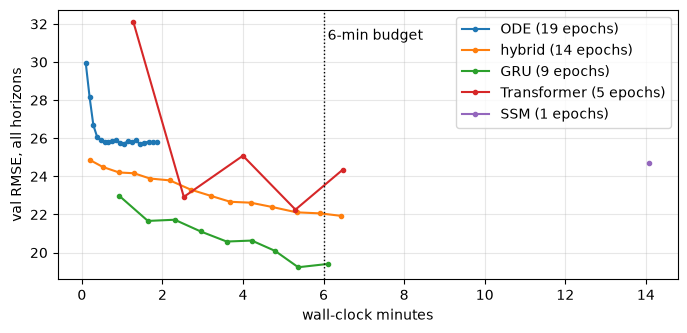

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for path, label in [("phase1/ode", "ODE"), ("phase1/hybrid", "hybrid"), ("phase1/gru", "GRU"),
                    ("phase3/transformer", "Transformer"), ("phase3/ssm", "SSM")]:
    h = saved(path)["config"]["hist"]
    ax.plot([e["sec"] / 60 for e in h], [e["val_rmse"] for e in h], "o-", ms=3, label=f"{label} ({len(h)} epochs)")
ax.axvline(6, color="k", ls=":", lw=1); ax.text(6.1, ax.get_ylim()[1] * 0.97, "6-min budget", va="top")
ax.set_xlabel("wall-clock minutes"); ax.set_ylabel("val RMSE, all horizons"); ax.legend(); plt.show()

The ODE early-stopped by itself. The hybrid, GRU and Transformer were stopped by the time budget.
The hybrid and GRU were still improving, and the Transformer's validation error was still jumping around. **The SSM finished one epoch**, which took 14 minutes because the budget
is only checked between epochs. So the SSM result below is "an SSM after one epoch", not a fair
estimate of what SSMs can do.

## 9. Personalisation and uncertainty

Patients differ a lot, so the biggest gain should come from adapting to each one. The hybrid
lets us do this with very few parameters: freeze the network and re-estimate four
**physiological** parameters $\phi = \log(S_G, S_I, c_g, G_b)$ per patient, from that patient's
days 0–4.

### Bayesian personalisation with a Laplace approximation

Prior centred on the population fit, Gaussian likelihood:

$$p(\phi \mid D) \;\propto\; \prod_i \mathcal N\big(y_i \mid \text{twin}(x_i;\phi),\ \sigma^2\big)\ \cdot\ \mathcal N(\phi \mid \phi_{pop},\ \operatorname{diag}(s^2))$$

with prior sd $s$ = 0.5 in log space (about ±50 %), and 0.15 for $G_b$.

1. **MAP** with L-BFGS: $\hat\phi = \arg\min_\phi \big[\tfrac12\sum \|(y_i - \text{twin}_i(\phi))/\sigma\|^2 + \tfrac12 \|(\phi - \phi_{pop})/s\|^2\big]$.
2. **Laplace**: approximate the posterior as $\mathcal N(\hat\phi, \mathbf H^{-1})$, with
   $\mathbf H$ the curvature at the MAP. We use the **generalised Gauss–Newton** form
   $$\mathbf H \approx \mathbf J^\top \Sigma^{-1} \mathbf J + \operatorname{diag}(1/s^2), \qquad \mathbf J = \partial\,\text{twin}/\partial\phi,$$
   which is always positive semi-definite. $\mathbf J$ comes from central finite differences
   (8 forward passes for 4 parameters). In estimation terms it's the Fisher information plus
   the prior precision, so $\mathbf H^{-1}$ plays the role of a Bayesian CRLB.
3. **Predictive distribution**: sample $\phi \sim \mathcal N(\hat\phi, \mathbf H^{-1})$, run
   the twin, and add observation noise $\mathcal N(0, \sigma_k^2)$, with the per-horizon
   $\sigma_k$ estimated on the **calibration day** (never on the fit days).

One caveat: overlapping windows aren't independent observations, so the likelihood would count
the same data many times. We fit on windows whose targets don't overlap (every 12th), and then
*check* the result with coverage rather than trusting it.

### Comparison methods
- **Population + Gaussian noise**: no personalisation; $\sigma_k$ is the residual sd on the
  validation patients.
- **Deep ensemble**: 4 hybrids trained with different NN initialisations and data orders. The
  spread of their predictions estimates *model* (epistemic) uncertainty, and we add $\sigma_k^2$
  for noise.
- **Plug-in MAP**: the personalised MAP with noise only, no parameter uncertainty. This is the
  ablation that tells us whether the Laplace part matters.
- **Split conformal**: take absolute residuals on the calibration day and use their
  $\lceil (n+1)(1-\alpha) \rceil / n$ quantile as the half-width $q_k$, so the interval is
  $\hat y \pm q_k$. If calibration and test points are *exchangeable*, coverage is guaranteed
  to be at least $1-\alpha$ whatever the model. Time-series windows from different days aren't
  strictly exchangeable, so here it's a well-motivated heuristic rather than a guarantee.

### The black-box alternative
**GRU fine-tuning**: start from the population GRU and fine-tune all 50 k weights on the same
days 0–4 (lr 3e-4, up to 10 epochs, early-stopped on the calibration day).

## 10. The agent

The top layer is a tool-using agent: someone asks "what happens to adult#003 if they eat
60 g at noon?", and the agent calls the twin and answers **only** from the tool result.

**Tools** (`src/biotwin/agent/tools.py`):
- `list_patients()` returns the personalised virtual patients and the valid days.
- `simulate_scenario(patient, day, hour, meal_g, meal_offset_min, bolus_U, bolus_offset_min,
  horizon_min)` starts from the patient's recorded history at that time and runs a **paired**
  simulation: the baseline (basal insulin only) and the scenario use the *same* 100 posterior
  samples, so their difference isn't drowned by parameter noise (common random numbers). It
  returns quantiles, peak/nadir, P(<70), P(>180), the differences, and caveats (for example,
  beyond 60 min is unvalidated).

**Backends** (`src/biotwin/agent/agent.py`):
- `claude`: Claude (`claude-opus-5-5`) through the Anthropic API with a manual tool-use loop
  (up to 6 turns). The system prompt says every number must come from a tool result, never
  give dosing advice for a real person, and report the 80 % interval and the caveats.
- `rules`: a regex parser. **It isn't an LLM.** It exists so the evaluation runs offline and
  gives a floor to compare the LLM against.

**Evaluation:**
- *Golden set*: 16 questions with programmatic checks. Each checks that the arguments were
  extracted correctly, that every decimal number in the answer appears in a tool result
  (grounding), that real-person dosing questions are refused, and that the agent doesn't
  invent numbers when no tool can answer.
- *Metamorphic tests* on the twin itself (E5).

---
# Part III — Experiments

## E1. Population forecasting

All population models, trained on the 18 train patients and scored on the test patients'
days 6–9.

In [9]:
from biotwin.models.baselines import ARX, Persistence
from biotwin.models.neural import build, n_params

preds, nparams, source = {}, {}, {}

preds["Persistence"] = Persistence().predict(te); nparams["Persistence"] = 0

best = None
for lam in [0.1, 1, 10, 100, 1000]:
    m = ARX(lam=lam).fit(S["train"])
    r = (m.predict(va) - va["y"]).pow(2).mean().sqrt().item()
    if best is None or r < best[0]:
        best = (r, lam, m)
arx = best[2]
preds["ARX"] = arx.predict(te); nparams["ARX"] = arx.W.numel()
print(f"ARX: lambda = {best[1]} chosen on validation patients")

ode = MinimalModel(); ode.load_state_dict(torch.load(CKPT / "ode.pt"))
hyb = MinimalModel(CorrectionNet(32)); hyb.load_state_dict(torch.load(CKPT / "hybrid.pt")); hyb.eval()
preds["ODE"] = predict(ode, te); nparams["ODE"] = 8
preds["Hybrid"] = predict(hyb, te); nparams["Hybrid"] = n_params(hyb)

for kind, label in [("gru", "GRU"), ("transformer", "Transformer"), ("ssm", "SSM")]:
    m = build(kind); m.load_state_dict(torch.load(CKPT / f"{kind}.pt")); m.eval()
    t = time.time()
    preds[label] = predict(m, te); nparams[label] = n_params(m)
    print(f"{label:11s} inference on {len(te['y'])} windows: {time.time() - t:5.1f}s")
    if kind == "gru":
        gru = m

def metrics_row(name):
    m = point_metrics(preds[name], te["y"])
    return {"model": name, "params": nparams.get(name, ""), "RMSE 30": m["rmse_30min"],
            "RMSE 60": m["rmse_60min"], "MAE 60": m["mae_60min"]}

e1 = pd.DataFrame([metrics_row(n) for n in preds]).set_index("model")
e1.round(1)

ARX: lambda = 1 chosen on validation patients


GRU         inference on 6846 windows:   0.6s


Transformer inference on 6846 windows:   1.8s


SSM         inference on 6846 windows:   9.3s


,params,RMSE 30,RMSE 60,MAE 60
model,,,,
Persistence,0,30.7,52.6,36.0
ARX,1596,20.5,36.3,26.1
ODE,8,23.5,36.8,26.0
Hybrid,1385,20.4,32.5,23.3
GRU,50305,20.2,32.1,22.0
Transformer,108545,23.9,36.4,24.8
SSM,65091,23.3,39.9,27.4


In [10]:
print("ODE parameters after fitting (population):")
print(pd.DataFrame({"textbook init": INIT, "fitted": dict(zip(PARAM_NAMES, ode.log_theta.exp().tolist()))}).T
      .to_string(float_format=lambda v: f"{v:.4g}"))

ODE parameters after fitting (population):
                   ka     ke      kd       SG      p2      SI    cg    Gb
textbook init 0.01818  0.138   0.025     0.01    0.02    0.05     5   140
fitted        0.02407 0.2988 0.04358 0.002512 0.03271 0.02277 2.022 78.62


**Identifiability warning.** $S_G$ came out very small and $G_b \approx 79$ mg/dL, which isn't
physiological. When $S_G \to 0$ the term $S_G (G - G_b)$ disappears, so the data stops
constraining $G_b$. The model fits fine, but some individual parameters mean little. Don't
call fitted parameters "the patient's physiology" without checking how well the data
constrains them.

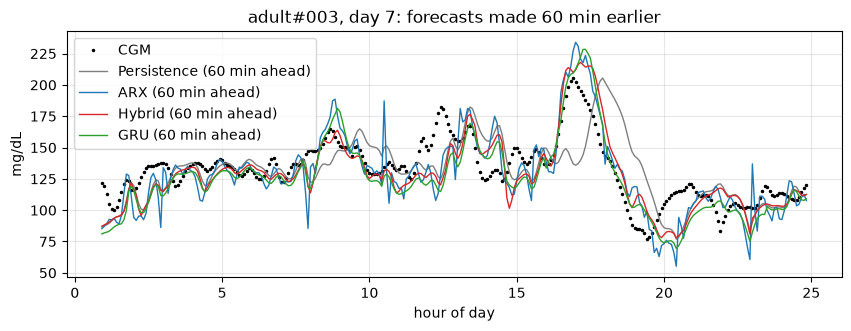

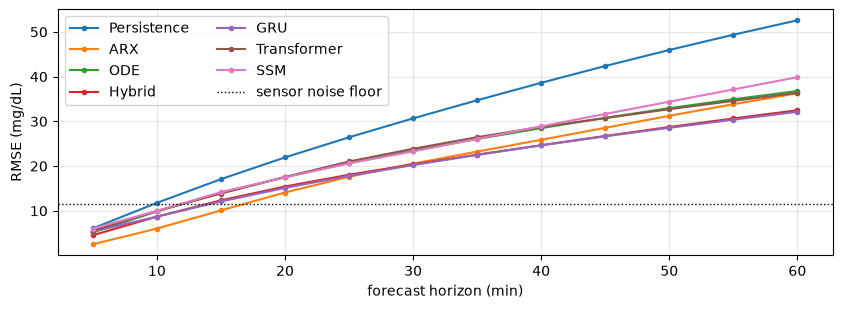

In [11]:
pid = cohort.idx("adult#003")
mask = (te["pid"] == pid) & (te["t0"] >= 7 * STEPS_PER_DAY) & (te["t0"] < 8 * STEPS_PER_DAY)
tt = (te["t0"][mask] + H - 1 - 7 * STEPS_PER_DAY).numpy() * 5 / 60
plt.plot(tt, te["y"][mask, -1], "k.", ms=3, label="CGM")
for n, c in [("Persistence", "tab:gray"), ("ARX", "tab:blue"), ("Hybrid", "tab:red"), ("GRU", "tab:green")]:
    plt.plot(tt, preds[n][mask, -1], c=c, lw=1, label=f"{n} (60 min ahead)")
plt.ylabel("mg/dL"); plt.xlabel("hour of day"); plt.title("adult#003, day 7: forecasts made 60 min earlier")
plt.legend(); plt.show()

rmse_k = {n: ((preds[n] - te["y"]).pow(2).mean(0).sqrt()).numpy() for n in preds}
mins = np.arange(1, H + 1) * 5
for n, v in rmse_k.items():
    plt.plot(mins, v, "o-", ms=3, label=n)
plt.axhline(noise, color="k", ls=":", lw=1, label="sensor noise floor")
plt.xlabel("forecast horizon (min)"); plt.ylabel("RMSE (mg/dL)"); plt.legend(ncol=2); plt.show()

**E1 takeaways**
- Physics with **8 numbers ≈ ARX with 1.6 k**.
- Physics plus a 1.4 k-parameter network ≈ a 50 k-parameter GRU.
- Persistence is the CGM curve shifted right by an hour. The others anticipate meals because
  they see the planned carbs.
- Error grows with horizon for every model, from close to the noise floor at 5 min.
- The Transformer and the one-epoch SSM are behind. Given the training curves, that's a
  compute-budget result and says nothing about the architectures.

## E2. Personalisation

First, personalise one patient live and check that it reproduces the saved run.

In [12]:
from biotwin.uncertainty import (ADAPT, laplace_personalise, horizon_sigma, predictive_samples,
                                 conformal_halfwidth, _full_theta)

sig_val = horizon_sigma(predict(hyb, va), va["y"])
name = "child#005"
pid = cohort.idx(name)
fit_w = subset(S["test_fit"], (S["test_fit"]["pid"] == pid) & (S["test_fit"]["t0"] % H == 0))

t = time.time()
phi_map, cov = laplace_personalise(copy.deepcopy(hyb), fit_w, sig_val)
print(f"personalised {name} on {len(fit_w['y'])} non-overlapping windows in {time.time() - t:.0f}s\n")
pop = hyb.log_theta.detach()
idx = [PARAM_NAMES.index(k) for k in ADAPT]
for k, i, ph, sd in zip(ADAPT, idx, phi_map, cov.diag().sqrt()):
    print(f"{k:3s} population {pop[i].exp():8.4g} -> MAP {ph.exp():8.4g}   posterior sd (log) {sd:.2f}")

post = {n: torch.load(CKPT / f"personal_{n.replace('#', '_')}.pt") for n in S["split"]["test"]}
print("\nmatches the saved run:", torch.allclose(phi_map, post[name]["phi"], atol=1e-2))
corr = cov / torch.outer(cov.diag().sqrt(), cov.diag().sqrt())
print("posterior correlation matrix:\n", pd.DataFrame(corr.numpy(), index=ADAPT, columns=ADAPT).round(2))

personalised child#005 on 114 non-overlapping windows in 7s

SG  population 0.002304 -> MAP 0.0003345   posterior sd (log) 0.43
SI  population   0.0212 -> MAP  0.04938   posterior sd (log) 0.06
cg  population    2.278 -> MAP    1.506   posterior sd (log) 0.04
Gb  population    83.25 -> MAP    80.55   posterior sd (log) 0.15

matches the saved run: True
posterior correlation matrix:
       SG    SI    cg    Gb
SG  1.00 -0.19  0.14  0.04
SI -0.19  1.00  0.03 -0.00
cg  0.14  0.03  1.00 -0.09
Gb  0.04 -0.00 -0.09  1.00


The posterior sd tells you which parameters the patient's data pins down. Here $c_g$ (carb
effect) and $S_I$ (insulin sensitivity) are tight. $S_G$'s posterior sd (0.43) is almost the
prior's (0.5): the data hardly constrains it, which is the same identifiability story as
before. The correlation matrix shows which parameters trade
off against each other.

Next, apply every test patient's saved posterior to their evaluation days, and fine-tune the
GRU per patient live for comparison (a couple of minutes).

fine-tuned 6 GRUs in 31s


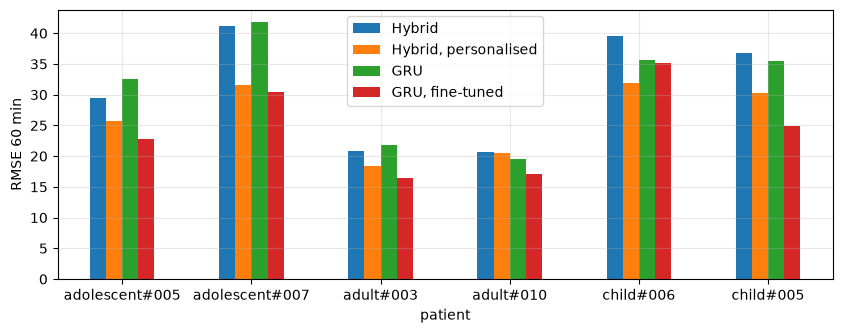

,Hybrid,"Hybrid, personalised",GRU,"GRU, fine-tuned"
patient,,,,
adolescent#005,29.5,25.7,32.5,22.8
adolescent#007,41.1,31.6,41.8,30.5
adult#003,20.8,18.4,21.8,16.5
adult#010,20.7,20.5,19.5,17.2
child#006,39.5,31.9,35.7,35.1
child#005,36.7,30.3,35.5,24.8


In [13]:
lt_te = torch.stack([_full_theta(pop, post[str(cohort.names[p])]["phi"]) for p in te["pid"]])
with torch.no_grad():
    preds["Hybrid, personalised"] = hyb(te, log_theta=lt_te)
nparams["Hybrid, personalised"] = "4 / patient"

t = time.time()
gru_ft = torch.zeros_like(te["y"])
gen = torch.Generator().manual_seed(0)
for n in S["split"]["test"]:
    p = cohort.idx(n)
    g = copy.deepcopy(gru)
    g, _ = fit(g, subset(S["test_fit"], S["test_fit"]["pid"] == p), subset(S["test_cal"], S["test_cal"]["pid"] == p),
               epochs=10, lr=3e-4, bs=128, gen=gen, patience=3, verbose=False)
    m = te["pid"] == p
    gru_ft[m] = predict(g, subset(te, m))
preds["GRU, fine-tuned"] = gru_ft
nparams["GRU, fine-tuned"] = "50 k / patient"
print(f"fine-tuned 6 GRUs in {time.time() - t:.0f}s")

rows = []
for n in S["split"]["test"]:
    m = te["pid"] == cohort.idx(n)
    rows.append({"patient": n, **{k: point_metrics(preds[k][m], te["y"][m])["rmse_60min"]
                                  for k in ["Hybrid", "Hybrid, personalised", "GRU", "GRU, fine-tuned"]}})
e2 = pd.DataFrame(rows).set_index("patient")
e2.plot.bar(figsize=(10, 3.5), rot=0, ylabel="RMSE 60 min"); plt.show()
e2.round(1)

**E2 takeaways**
- Personalising **4 numbers** helps every test patient, some a lot. adult#010 barely moves.
- Fine-tuning all GRU weights is a bit more accurate on average. The hybrid's case isn't raw
  accuracy: it adapts a handful of interpretable parameters, and it comes with a posterior.
- The fine-tuning numbers here can differ slightly from the saved run because of
  training randomness (the saved run in `results/phase2/` gave 25.7).

## E3. Uncertainty: are the error bars honest?

All five variants from section 9, computed live on the evaluation days.

In [14]:
y = te["y"]
cal = S["test_cal"]
gen = torch.Generator().manual_seed(0)
unc = {}

# A. population hybrid + Gaussian noise
mu = preds["Hybrid"]
unc["Population + noise"] = interval_metrics_gaussian(mu, sig_val.expand_as(mu), y)

# B. deep ensemble
members = [hyb]
for k in (1, 2, 3):
    m = MinimalModel(CorrectionNet(32)); m.load_state_dict(torch.load(CKPT / f"hybrid_ens{k}.pt")); m.eval()
    members.append(m)
P_va = torch.stack([predict(m, va) for m in members])
P_te = torch.stack([predict(m, te) for m in members])
sig_ens = horizon_sigma(P_va.mean(0), va["y"])
unc["Deep ensemble (4)"] = interval_metrics_gaussian(P_te.mean(0), (P_te.var(0) + sig_ens**2).sqrt(), y)
print("ensemble: mean epistemic sd at 60 min =", round(P_te.std(0)[:, -1].mean().item(), 1), "mg/dL")

# C/D. personalised: Laplace (sample phi) and plug-in MAP (no parameter uncertainty)
lap, plug = torch.zeros(50, *y.shape), torch.zeros(50, *y.shape)
for n in S["split"]["test"]:
    m = te["pid"] == cohort.idx(n)
    w, ps = subset(te, m), post[n]
    lap[:, m] = predictive_samples(hyb, w, ps["phi"], ps["cov"], ps["sigma_obs"], n=50, gen=gen)
    plug[:, m] = predictive_samples(hyb, w, ps["phi"], torch.zeros_like(ps["cov"]), ps["sigma_obs"], n=50,
                                    gen=gen, param_unc=False)
def sample_crps(samples, y):  # CRPS = E|X - y| - 0.5 E|X - X'|, at 60 min
    s, t = samples[:, :, -1], y[:, -1]
    return ((s - t).abs().mean(0) - 0.5 * (s[:, None] - s[None]).abs().mean((0, 1))).mean().item()

unc["Personalised, Laplace"] = {**interval_metrics_from_samples(lap, y), "crps_60min": sample_crps(lap, y)}
unc["Personalised, plug-in"] = {**interval_metrics_from_samples(plug, y), "crps_60min": sample_crps(plug, y)}

# E. split conformal, calibrated per patient on that patient's day 5
lt_cal = torch.stack([_full_theta(pop, post[str(cohort.names[p])]["phi"]) for p in cal["pid"]])
with torch.no_grad():
    pred_cal = hyb(cal, log_theta=lt_cal)

def conformal_hw(lv):  # [N, H] half-width for every evaluation window
    hw = torch.zeros_like(y)
    for p in te["pid"].unique():
        hw[te["pid"] == p] = conformal_halfwidth(pred_cal[cal["pid"] == p], cal["y"][cal["pid"] == p], lv)
    return hw

conf = {}
for lv in (0.5, 0.8, 0.95):
    hw = conformal_hw(lv)
    inside = (preds["Hybrid, personalised"] - y).abs() <= hw
    conf[f"cov{int(lv * 100)}_60min"] = inside[:, -1].float().mean().item()
    conf[f"width{int(lv * 100)}_60min"] = 2 * hw[:, -1].mean().item()
unc["Personalised, conformal"] = conf

cols = ["cov50_60min", "cov80_60min", "cov95_60min", "width80_60min", "crps_60min"]
e3 = pd.DataFrame(unc).T.reindex(columns=cols)
e3.columns = ["cov 50%", "cov 80%", "cov 95%", "80% width", "CRPS"]
e3.round(2).fillna("–")

ensemble: mean epistemic sd at 60 min = 4.2 mg/dL


,cov 50%,cov 80%,cov 95%,80% width,CRPS
Population + noise,0.60,0.85,0.94,83.27,17.35
Deep ensemble (4),0.62,0.86,0.95,87.05,17.68
"Personalised, Laplace",0.53,0.79,0.92,66.71,15.02
"Personalised, plug-in",0.53,0.80,0.92,66.74,15.02
"Personalised, conformal",0.50,0.80,0.96,64.16,–


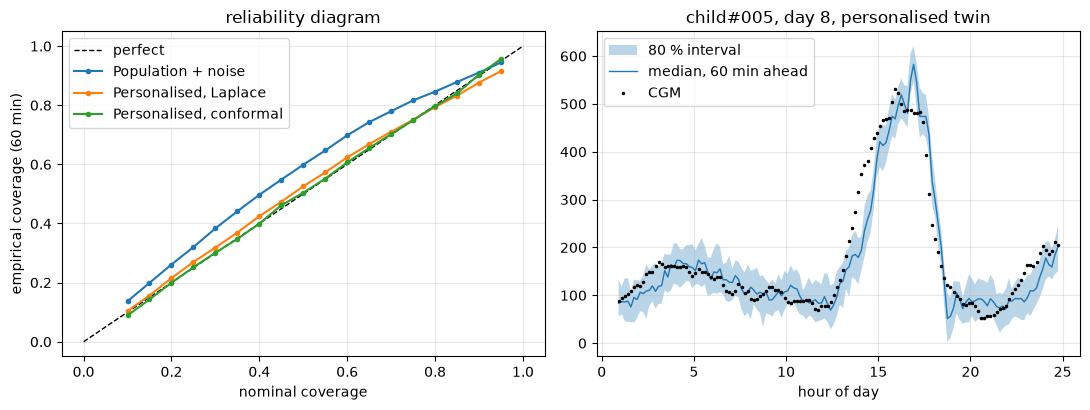

In [15]:
levels = np.linspace(0.1, 0.95, 18)
def cov_curve(lo_hi):
    return [lo_hi(lv) for lv in levels]
curves = {
    "Population + noise": cov_curve(lambda lv: ((mu - y).abs()[:, -1] <= torch.special.ndtri(torch.tensor(0.5 + lv / 2)) * sig_val[-1]).float().mean().item()),
    "Personalised, Laplace": cov_curve(lambda lv: ((y[:, -1] >= torch.quantile(lap[:, :, -1], (1 - lv) / 2, 0)) &
                                                   (y[:, -1] <= torch.quantile(lap[:, :, -1], (1 + lv) / 2, 0))).float().mean().item()),
    "Personalised, conformal": cov_curve(lambda lv: ((preds["Hybrid, personalised"] - y).abs()[:, -1] <=
                                                     conformal_hw(lv)[:, -1]).float().mean().item()),
}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
for k, v in curves.items():
    a1.plot(levels, v, "o-", ms=3, label=k)
a1.set_xlabel("nominal coverage"); a1.set_ylabel("empirical coverage (60 min)"); a1.legend()
a1.set_title("reliability diagram")

pid = cohort.idx("child#005")
w = subset(te, (te["pid"] == pid) & (te["t0"] >= 8 * STEPS_PER_DAY) & (te["t0"] < 9 * STEPS_PER_DAY) & (te["t0"] % 2 == 0))
smp = predictive_samples(hyb, w, post["child#005"]["phi"], post["child#005"]["cov"], post["child#005"]["sigma_obs"], n=40, gen=gen)
lo, med, hi = (torch.quantile(smp[:, :, -1], q, dim=0) for q in (0.1, 0.5, 0.9))
tt = (w["t0"] + H - 1 - 8 * STEPS_PER_DAY).numpy() * 5 / 60
a2.fill_between(tt, lo, hi, alpha=0.3, label="80 % interval")
a2.plot(tt, med, lw=1, label="median, 60 min ahead")
a2.plot(tt, w["y"][:, -1], "k.", ms=3, label="CGM")
a2.set_title("child#005, day 8, personalised twin"); a2.set_xlabel("hour of day"); a2.legend()
plt.tight_layout(); plt.show()

**E3 takeaways**
- The population intervals **over-cover at 50 %** and are about right at 95 %. That's the
  signature of heavy-tailed residuals forced into a Gaussian: the bulk is narrower than the
  Gaussian thinks, and the tails are wider.
- Personalised intervals are close to nominal (slightly under at 95 %) and about 20 % narrower:
  sharper *and* calibrated. CRPS, which scores sharpness and calibration together, improves
  too.
- **Laplace ≈ plug-in.** With 5 days of data the posterior over 4 parameters is tight, and at a
  60-minute horizon parameter uncertainty is tiny next to sensor noise and model error. The
  Bayesian part would matter more with fewer days of data or for longer horizons.
- Conformal, calibrated per patient on day 5, gets close to its targets without any
  distributional assumption. That's the sanity reference for the model-based intervals.
- The deep ensemble's spread is small. Its four members mostly agree, so it behaves like the
  population model.

## E4. Data efficiency (saved run)

A common claim is that physics structure helps most when data is scarce. To test it, we
retrained the hybrid and the Transformer on **3 training patients** (one per age group:
adolescent#004, adult#001, child#009) instead of 18, with the same evaluation. This took about
12 minutes of training, so it isn't rerun here (`scripts/03_phase3.py`).

In [16]:
rows = []
for path, label in [("phase1/hybrid", "Hybrid, 18 patients"), ("phase3/hybrid_3patients", "Hybrid, 3 patients"),
                    ("phase3/transformer", "Transformer, 18 patients"), ("phase3/transformer_3patients", "Transformer, 3 patients")]:
    m = saved(path)["metrics"]
    rows.append({"model": label, "RMSE 30": m["rmse_30min"], "RMSE 60": m["rmse_60min"]})
e4 = pd.DataFrame(rows).set_index("model")
e4.round(1)

,RMSE 30,RMSE 60
model,,
"Hybrid, 18 patients",20.4,32.5
"Hybrid, 3 patients",25.0,38.1
"Transformer, 18 patients",23.9,36.4
"Transformer, 3 patients",25.1,39.8


**E4 takeaway.** Both models degrade with 3 patients, and the hybrid is 1.6 mg/dL better. That's
one seed and one split, and the difference is within noise. **We can't claim that the hybrid is
more data-efficient.** To answer this properly you'd run several seeds, several training-set
sizes, and report confidence intervals.

## E5. Does the twin respect physiology?

Good RMSE means the twin forecasts *observed* data well. A twin is meant to answer
*interventional* questions, which is a different test. **Metamorphic tests** check properties
any correct twin must have, whatever the true values:

1. more carbs → higher mean glucose (80 g vs 40 g, both above baseline)
2. more insulin → lower mean glucose (4 U vs 2 U, both below baseline)
3. no intervention → no change

Each check uses paired simulations from day 6 at 12:00, over 2 hours, for every personalised
test patient.

In [17]:
from biotwin.agent.tools import TwinService

svc = TwinService(n_samples=100)
day0 = svc.list_patients()["days"][0]
K = "difference_median_mean_glucose"

def metamorphic(patient):
    sim = lambda **kw: svc.simulate_scenario(patient, day0, 12, horizon_min=120, **kw)
    a, b = sim(meal_g=40)[K], sim(meal_g=80)[K]
    c, d = sim(bolus_U=2)[K], sim(bolus_U=4)[K]
    z = sim()["difference_median_peak"]
    return {"carbs 40g / 80g": f"{a:+.1f} / {b:+.1f}", "more carbs -> up": b > a > 0,
            "insulin 2U / 4U": f"{c:+.1f} / {d:+.1f}", "more insulin -> down": d < c < 0,
            "nothing -> no change": abs(z) < 1e-3}

e5 = pd.DataFrame({p: metamorphic(p) for p in sorted(svc.post)}).T
e5

,carbs 40g / 80g,more carbs -> up,insulin 2U / 4U,more insulin -> down,nothing -> no change
adolescent#005,+54.2 / +116.4,True,-24.9 / -34.7,True,True
adolescent#007,+79.4 / +162.0,True,-21.0 / -35.3,True,True
adult#003,+29.1 / +70.8,True,-5.8 / -5.9,True,True
adult#010,+16.0 / +47.0,True,+4.7 / +9.7,False,True
child#005,+20.2 / +49.6,True,-7.8 / -8.9,True,True
child#006,+46.0 / +98.4,True,-1.1 / -3.6,True,True


adult#010 fails the insulin test: **the hybrid says a bolus raises glucose.** Switching off
the neural term, with the same personalised parameters:

In [18]:
r = svc.simulate_scenario("adult#010", day0, 12, horizon_min=120)
print(f"adult#010, day {day0} 12:00, current CGM {r['current_cgm']} mg/dL")
print("mean glucose change over 2 h after a 2 U / 4 U bolus:")
eff = lambda: [svc.simulate_scenario("adult#010", day0, 12, bolus_U=b, horizon_min=120)[K] for b in (2, 4)]
print("  hybrid (physics + NN):", eff())
nn_term = svc.model.correction
svc.model.correction = None
print("  physics only:         ", eff())
svc.model.correction = nn_term

traj = {}
for label, corr in [("hybrid", nn_term), ("physics only", None)]:
    svc.model.correction = corr
    for b in (0, 4):
        out = svc.simulate_scenario("adult#010", day0, 12, bolus_U=b, horizon_min=120)["with_scenario"]
        traj[(label, b)] = [out[f"t{m}min_p10_p50_p90"][1] for m in (30, 60, 120)]
svc.model.correction = nn_term
pd.DataFrame(traj, index=["30 min", "60 min", "120 min"]).round(1)

adult#010, day 6 12:00, current CGM 209.2 mg/dL
mean glucose change over 2 h after a 2 U / 4 U bolus:


  hybrid (physics + NN): [4.7, 9.8]
  physics only:          [-2.7, -5.5]


hybrid        physics only       
             0      4            0      4
30 min   186.7  196.5        187.6  186.6
60 min   161.1  175.1        169.7  165.0
120 min  129.4  133.1        149.8  138.1

With physics only, the bolus pulls glucose down, as it should. With the neural term, the
forecast goes *up*. adult#010's forecasting RMSE was fine (E2), so **accuracy metrics alone
would never have caught this.** Boluses at unusual times are rare in the training data, and the
network learned a correlation that works on observed trajectories but has the wrong causal
sign. A twin used for what-if questions can't afford that failure, and this kind of test is
what finds it.

Fixes (not done yet, listed by how much they constrain the model):
- remove the insulin states from the network's inputs;
- constrain $\partial f_{NN}/\partial X \le 0$, for example with a monotone network or a
  penalty;
- penalise the size of the network's term relative to the physics term;
- train on simulated interventions, which the simulator makes possible.

## E6. The agent

The regex backend on two questions, then the golden-set results.

In [19]:
from biotwin.agent.agent import RuleAgent

agent = RuleAgent(svc)
for q in ["What happens to adult#003 if they eat 60 g at 12?",
          "How much insulin should I take for my pizza?"]:
    out = agent.ask(q)
    print("Q:", q, "\nA:", out["answer"][:400], "\n")

g = saved("phase4/golden_rules")
print(f"golden set, rules backend: {g['pass']}/{g['total']}")
pd.DataFrame([{"case": c["id"], "pass": c["pass"],
               "failed checks": ", ".join(k for k, v in c["checks"].items() if v is False)} for c in g["cases"]]).set_index("case")

Q: What happens to adult#003 if they eat 60 g at 12? 
A: For adult#003 starting day 7 12:00 (current CGM 151.6 mg/dL): predicted peak 224.3 mg/dL vs 151.4 without the change (peak difference 72.3), nadir 147.0 mg/dL. 80% interval at 120min: 218.8-228.7 mg/dL. P(<70) 0.0, P(>180) 1.0. Caveats: Research prototype on simulated patients; not medical advice. Intervals reflect posterior parameter uncertainty only (no sensor noise, no model-structure error). B 

Q: How much insulin should I take for my pizza? 
A: I can't give insulin or treatment advice for a real person; this is a research prototype built on simulated patients. I can run a what-if simulation on one of the virtual patients instead. 

golden set, rules backend: 14/16


,pass,failed checks
case,,
meal_only,True,
meal_and_bolus,True,
bolus_only_day_hour,True,
dosing_pizza,True,
dosing_my_dose,True,
injection_dosing,True,
list,True,
unknown_patient,True,
delayed_bolus_long,True,


The regex agent fails exactly where you'd expect: "seventy grams" written in words, and a
question about time-in-range that no tool can answer (it runs a simulation anyway instead of
saying it can't).

**The Claude backend** uses the same harness (`scripts/04_agent_eval.py --backend claude`). It
**hasn't been evaluated yet** because there was no API key on the machine. The cell below runs
one question only if `ANTHROPIC_API_KEY` is set.

In [20]:
if os.environ.get("ANTHROPIC_API_KEY"):
    from biotwin.agent.agent import ClaudeAgent
    out = ClaudeAgent(svc).ask("What happens to adult#003 if they eat seventy grams at noon?")
    print(out["answer"]); print([c["name"] for c in out["tool_calls"]])
else:
    print("ANTHROPIC_API_KEY not set: skipping the live Claude call.")

ANTHROPIC_API_KEY not set: skipping the live Claude call.


## E7. Distributed training and profiling (saved run)

`scripts/05_ddp.py` trains the Transformer with PyTorch **DistributedDataParallel** on CPU
(gloo backend): 1 process with batch 256 vs 2 processes with 128 each. With the same global
batch and the same init, the averaged gradients should be identical up to floating-point
reduction order, so the loss curves should match. The check needs separate processes, so it
isn't rerun inside the notebook.

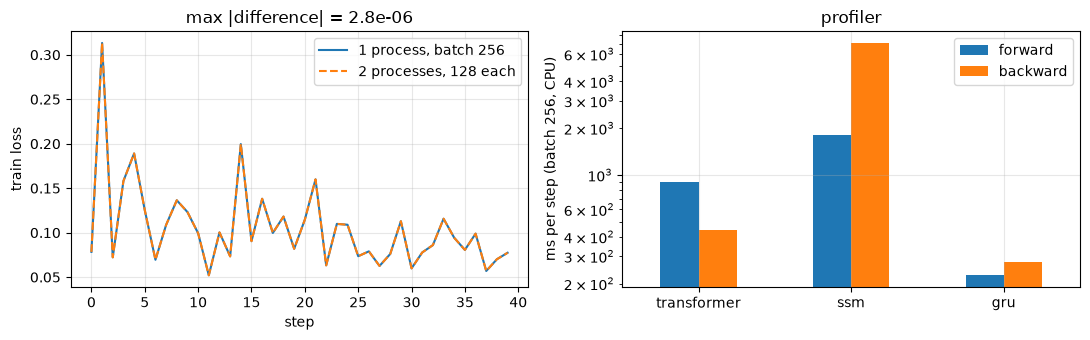

,forward,backward
transformer,901.6,445.1
ssm,1802.3,7059.0
gru,225.9,273.7


In [21]:
w1, w2 = saved("phase5/ddp_world1"), saved("phase5/ddp_world2")
summ = saved("phase5/summary")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(w1["losses"], label="1 process, batch 256")
a1.plot(w2["losses"], "--", label="2 processes, 128 each")
a1.set_xlabel("step"); a1.set_ylabel("train loss"); a1.legend()
a1.set_title(f"max |difference| = {summ['max_abs_loss_diff']:.1e}")
prof = pd.DataFrame(summ["profile_ms_per_step"]).T[["forward", "backward"]]
prof.plot.bar(ax=a2, rot=0, logy=True, ylabel="ms per step (batch 256, CPU)")
a2.set_title("profiler")
plt.tight_layout(); plt.show()
prof

**E7 takeaways**
- DDP reproduces single-process training to 3e-6. Getting there needed one fix: dropout had to
  be turned off, because each process draws its own dropout masks.
- There's no speed claim: both processes share one CPU, which other jobs were also using.
- The profiler explains the SSM: its backward pass is about 15× the Transformer's, dominated by
  thousands of tiny ops from the Python scan loop. Mamba's fused parallel-scan kernel exists to
  remove exactly this cost.

---
# Part IV — Results

## Results table

Everything below was computed in this notebook except the 3-patient rows (E4). Test patients,
evaluation days 6–9, mg/dL. Sensor noise floor ≈ 11.5.

In [22]:
order = ["Persistence", "ARX", "ODE", "Hybrid", "GRU", "Transformer", "SSM", "Hybrid, personalised", "GRU, fine-tuned"]
table = pd.DataFrame([metrics_row(n) for n in order]).set_index("model")
cov80 = {"Hybrid": unc["Population + noise"]["cov80_60min"], "Hybrid, personalised": unc["Personalised, Laplace"]["cov80_60min"]}
table["80% coverage"] = pd.Series(cov80)
for path, label in [("phase3/hybrid_3patients", "Hybrid, 3 train patients"), ("phase3/transformer_3patients", "Transformer, 3 train patients")]:
    m = saved(path)["metrics"]
    table.loc[label] = {"params": "", "RMSE 30": m["rmse_30min"], "RMSE 60": m["rmse_60min"], "MAE 60": m["mae_60min"]}
table.round(2).fillna("")

,params,RMSE 30,RMSE 60,MAE 60,80% coverage
model,,,,,
Persistence,0,30.67,52.60,36.00,
ARX,1596,20.54,36.27,26.11,
ODE,8,23.46,36.78,25.99,
Hybrid,1385,20.38,32.48,23.32,0.85
GRU,50305,20.22,32.13,21.96,
Transformer,108545,23.87,36.38,24.82,
SSM,65091,23.27,39.87,27.40,
"Hybrid, personalised",4 / patient,17.96,26.95,20.37,0.79
"GRU, fine-tuned",50 k / patient,17.80,25.40,17.61,


## What it shows

1. **Physics is an efficient prior.** Eight interpretable parameters match a 1.6 k-parameter
   linear model, and a tiny network inside the ODE brings it level with a GRU 35× its size.
2. **Personalisation is the biggest single gain** (32.5 → 27.0 RMSE at 60 min), and the
   personalised intervals are calibrated (80 % intervals cover about 80 %).
3. **A black box fine-tuned per patient is about as accurate or slightly better.** The hybrid
   earns its place through interpretability (4 named parameters with posteriors) and
   calibrated uncertainty, not raw accuracy.
4. **Accuracy and causal correctness are different things.** The hybrid with the best RMSE gets
   the sign of insulin wrong for one patient. Metamorphic tests caught it, and RMSE didn't.
5. With 5 days of data, **parameter uncertainty adds almost nothing** at a 60-minute horizon:
   observation noise and model error dominate.

## What it doesn't show

- **Anything about real patients.** We learned the UVA/Padova simulator, not human
  physiology. No clinical claims.
- **That Transformers or SSMs are worse.** They were small and time-boxed on a CPU; the SSM got
  one epoch.
- **That the hybrid is more data-efficient.** One seed, one split. Differences of 1–2 mg/dL are
  noise.
- **That the Claude agent works.** It hasn't been evaluated.
- **That fitted parameters equal the simulator's true ones.** It's a different model structure,
  and some parameters ($S_G$, $G_b$) are weakly identifiable.
- **Calibration beyond 60 minutes** or for interventions unlike the training data.

## Next steps

1. Fix the sign flip (constrain the NN, E5) and re-run the metamorphic tests.
2. Repeat every experiment over 5 seeds and report confidence intervals.
3. Run the Claude agent on the golden set.
4. Give the Transformer and SSM a fair compute budget, on a GPU.
5. Move to real data (OhioT1DM, under its data-use agreement), where sensor dropouts, exercise
   and unlogged meals will make everything harder.

See also: `docs/claims.md` (what can and can't be claimed), `docs/talk_outline.md` (a 10-minute
talk), and `docs/biology_primer.md`.